
# ILLM Lab 2 — TF‑IDF Normalization Ablation for Language Identification

**Builds on Lab 1's dataset, tokenizer, split, and logistic‑regression classifier.**
This notebook implements and compares **6 combinations** of TF and IDF weighting
schemes, all still hand‑written — **no `sklearn`** anywhere.

---

## 1. Deep analysis of the assignment

| # | Requirement | What it means concretely |
|---|---|---|
| 1a | TF normalized by **total number of words in the sentence** | Document‑length normalization: divide every feature's raw count by how many word tokens that sentence has. |
| 1b | TF normalized by **frequency of the most frequent word in the sentence** | Max‑normalization: divide every feature's raw count by the count of the single most‑repeated word in that sentence. |
| 2 | IDF normalized based on the **most frequent word across sentences** | Corpus‑level max‑df normalization: find the word (unigram) that appears in the most training sentences, and use *its* document frequency — instead of the total number of documents `N` — as the reference inside the IDF formula. |
| 3 | Logistic regression on all combinations of {unnormalized TF, TF‑1a, TF‑1b} × {unnormalized IDF, IDF‑2}; compare performance | `3 TF variants × 2 IDF variants = 6 combinations`, each trained with the **same** logistic‑regression architecture/hyperparameters as Lab 1, so the comparison isolates the effect of feature weighting, not the classifier. |

## 2. Formal definitions used in this notebook

Let a document `d` (one sentence) have:
* `count(t, d)` — raw occurrence count of feature `t` (a word 1/2‑gram or char
  2/3/4‑gram, exactly as extracted in Lab 1) inside `d`.
* `words(d)` — the list of **word tokens** in `d` (same regex tokenizer used to build
  word n‑grams). `n_words(d) = len(words(d))`.
* `max_word_freq(d)` — the count of the single most frequent word inside `words(d)`
  (e.g. if "the" appears 3 times in the sentence and nothing else repeats more, this
  is 3).

**Three TF variants** (applied to every feature `t` in `d`, word‑gram or char‑gram alike):

```
TF_raw(t, d)  = count(t, d)                                     # Lab 1 baseline
TF_len(t, d)  = count(t, d) / n_words(d)                        # 1a: sentence-length normalization
TF_max(t, d)  = count(t, d) / max_word_freq(d)                  # 1b: max-word-frequency normalization
```

Let `N` = number of training documents, `df(t)` = number of training documents
containing feature `t`, and `max_word_df` = the **highest document frequency among
all word‑unigram features** in the training vocabulary (i.e. the document frequency
of the single most common word across the whole training corpus).

**Two IDF variants** (smoothed the same way as Lab 1, just with a different reference
denominator):

```
IDF_std(t)   = ln( (1 + N)            / (1 + df(t)) ) + 1        # Lab 1 baseline
IDF_maxdf(t) = ln( (1 + max_word_df)  / (1 + df(t)) ) + 1        # 2: normalized by the most frequent word's df
```

Since `max_word_df <= N`, `IDF_maxdf(t) <= IDF_std(t)` for every term — the whole IDF
scale compresses, and the *reference point* for "how rare is this term" shifts from
"the whole corpus" to "as rare as the single most common word in the language" (which
gets an IDF near `ln(1)+1 = 1`, i.e. treated as carrying almost no information, exactly
as intended for a normalization anchored on the most frequent word).

**Combined weight**, for any of the 6 (TF variant, IDF variant) pairs:

```
weight(t, d) = TF_variant(t, d) * IDF_variant(t)
```

followed by the **same final L2 row‑normalization** used in Lab 1 for every one of the
6 variants — this is a deliberate control: L2‑normalizing every variant the same way
means any performance difference we observe is attributable to the *TF/IDF weighting
choice*, not to raw vector magnitude.

## 3. Plan for this notebook

```
Reload / rebuild the Lab 1 dataset (23,000 sentences, 23 languages)
        │  (same tokenizer, same 800/100/100 stratified split)
        ▼
TfidfFeatureBuilder.fit()  — tokenize ONCE, build vocabulary + df(t) + max_word_df
        │                     (shared by all 6 combinations — no redundant re-tokenizing)
        ▼
For each of the 6 (tf_mode, idf_mode) combinations:
        │   apply the corresponding TF formula + IDF formula + L2 normalize
        ▼
Train the SAME logistic regression architecture/hyperparameters as Lab 1
        │   (isolates the weighting effect from the optimizer)
        ▼
Evaluate with the SAME custom macro-F1 module as Lab 1, on val AND test
        ▼
Compare all 6 in one table + bar chart, discuss which normalization wins and why
```



## Section 1 — Environment Setup

Identical to Lab 1's setup — generic scientific Python plus `datasets`/
`huggingface_hub` only as a downloader. No `sklearn` import anywhere in this notebook.


In [1]:

import re
import os
import math
import random
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from tqdm.auto import tqdm

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("Environment ready.")


Environment ready.



## Section 2 — Language Inventory (same 23 IndicCorpV2 splits as Lab 1)


In [2]:

LANGUAGES = [
    {"code": "asm_Beng", "name": "Assamese",           "script": "Bengali-Assamese"},
    {"code": "ben_Beng", "name": "Bengali",             "script": "Bengali-Assamese"},
    {"code": "brx_Deva", "name": "Bodo",                "script": "Devanagari"},
    {"code": "doi_Deva", "name": "Dogri",               "script": "Devanagari"},
    {"code": "gom_Deva", "name": "Konkani (Goan)",      "script": "Devanagari"},
    {"code": "guj_Gujr", "name": "Gujarati",            "script": "Gujarati"},
    {"code": "hin_Deva", "name": "Hindi",               "script": "Devanagari"},
    {"code": "kan_Knda", "name": "Kannada",             "script": "Kannada"},
    {"code": "kas_Arab", "name": "Kashmiri",            "script": "Perso-Arabic"},
    {"code": "mai_Deva", "name": "Maithili",            "script": "Devanagari"},
    {"code": "mal_Mlym", "name": "Malayalam",           "script": "Malayalam"},
    {"code": "mar_Deva", "name": "Marathi",             "script": "Devanagari"},
    {"code": "mni_Mtei", "name": "Manipuri (Meitei)",   "script": "Meitei Mayek"},
    {"code": "npi_Deva", "name": "Nepali",              "script": "Devanagari"},
    {"code": "ory_Orya", "name": "Odia",                "script": "Odia"},
    {"code": "pan_Guru", "name": "Punjabi",             "script": "Gurmukhi"},
    {"code": "san_Deva", "name": "Sanskrit",            "script": "Devanagari"},
    {"code": "snd_Deva", "name": "Sindhi",              "script": "Devanagari"},
    {"code": "tam_Taml", "name": "Tamil",               "script": "Tamil"},
    {"code": "tel_Telu", "name": "Telugu",              "script": "Telugu"},
    {"code": "urd_Arab", "name": "Urdu",                "script": "Perso-Arabic"},
    {"code": "khasi",    "name": "Khasi",               "script": "Latin"},
    {"code": "santhali", "name": "Santali",             "script": "Ol Chiki"},
]

assert len(LANGUAGES) == 23
LABELS = [l["code"] for l in LANGUAGES]
LABEL2ID = {c: i for i, c in enumerate(LABELS)}
ID2LABEL = {i: c for c, i in LABEL2ID.items()}

pd.DataFrame(LANGUAGES)


,code,name,script
0,asm_Beng,Assamese,Bengali-Assamese
1,ben_Beng,Bengali,Bengali-Assamese
2,brx_Deva,Bodo,Devanagari
3,doi_Deva,Dogri,Devanagari
4,gom_Deva,Konkani (Goan),Devanagari
5,guj_Gujr,Gujarati,Gujarati
6,hin_Deva,Hindi,Devanagari
7,kan_Knda,Kannada,Kannada
8,kas_Arab,Kashmiri,Perso-Arabic
9,mai_Deva,Maithili,Devanagari



## Section 3 — Sentence Tokenizer (identical to Lab 1)

Same script‑aware splitter: handles the Devanagari danda `।`/`॥` and Arabic `۔`/`؟`
sentence‑enders in addition to `. ! ?`, with the same length/word‑count filters.


In [3]:

_SENTENCE_END = re.compile(r'(?<=[।॥.!?؟۔])\s+')
_LEADING_JUNK = re.compile(r'^(?:[>*\-•●▪·|]+|\(?\d{1,3}[.)]\s*)+')

MIN_SENT_CHARS = 20
MAX_SENT_CHARS = 400
MIN_SENT_WORDS = 4


def sentence_tokenize(paragraph: str):
    if not isinstance(paragraph, str) or not paragraph.strip():
        return []
    text = re.sub(r'\s+', ' ', paragraph).strip()
    raw_sentences = _SENTENCE_END.split(text)
    cleaned = []
    for s in raw_sentences:
        s = s.strip()
        s = _LEADING_JUNK.sub('', s).strip()
        if not s:
            continue
        n_chars = len(s)
        n_words = len(s.split())
        if MIN_SENT_CHARS <= n_chars <= MAX_SENT_CHARS and n_words >= MIN_SENT_WORDS:
            cleaned.append(s)
    return cleaned



## Section 4 — Reload the Lab 1 Dataset ("Use the same dataset you created in the
previous assignment")

To honor this requirement exactly, we **first try to load the CSV saved at the end of
Lab 1** (`indiccorp_lid_1000_per_lang.csv`, written in that notebook's Section 4). If
it isn't found next to this notebook (e.g. a fresh environment), we fall back to
rebuilding it with the **exact same** data‑collection code that Lab 1 ended up using
(streaming the raw `.txt` shards via `HfFileSystem`, since IndicCorpV2's `data_dir=`
config route was found to be unreliable) — so either way the resulting dataset is
identical in construction to Lab 1's.


In [4]:

RAW_DATA_PATH = "indiccorp_lid_1000_per_lang.csv"
TARGET_PER_LANGUAGE = 1111

if os.path.exists(RAW_DATA_PATH):
    print(f"Found existing Lab 1 dataset at '{RAW_DATA_PATH}' — loading it directly (no re-download).")
    df = pd.read_csv(RAW_DATA_PATH, encoding="utf-8")
else:
    print(f"'{RAW_DATA_PATH}' not found — rebuilding the Lab 1 dataset from IndicCorpV2 "
          f"(this needs internet access to huggingface.co and will take a while).")
    from huggingface_hub import HfFileSystem

    # Mapping based directly on the dataset's README (same as Lab 1).
    FILE_MAP = {
        "asm_Beng": "as.txt", "ben_Beng": "bn.txt", "brx_Deva": "bd.txt",
        "doi_Deva": "dg.txt", "gom_Deva": "gom.txt", "guj_Gujr": "gu.txt",
        "hin_Deva": "hi-", "kan_Knda": "kn.txt", "kas_Arab": "ks.txt",
        "mai_Deva": "mai.txt", "mal_Mlym": "ml.txt", "mar_Deva": "mr.txt",
        "mni_Mtei": "mni.txt", "npi_Deva": "ne.txt", "ory_Orya": "or.txt",
        "pan_Guru": "pa.txt", "san_Deva": "sa.txt", "snd_Deva": "sd.txt",
        "tam_Taml": "ta.txt", "tel_Telu": "te.txt", "urd_Arab": "ur.txt",
        "khasi": "kha.txt", "santhali": "sat.txt",
    }

    def collect_sentences_for_language(split_code: str, target_n: int = 1000,
                                        seed: int = RANDOM_SEED) -> list:
        """Stream text manually to skip corrupted web-scraping bytes."""
        fs = HfFileSystem()
        seen, sentences = set(), []
        repo_files = fs.ls("datasets/ai4bharat/IndicCorpV2/data", detail=False)
        prefix = FILE_MAP[split_code]
        target_files = [f for f in repo_files if f.split("/")[-1].startswith(prefix)]

        for file_path in target_files:
            with fs.open(file_path, "r", encoding="utf-8", errors="ignore") as f:
                for para in f:
                    if not para.strip():
                        continue
                    for sent in sentence_tokenize(para):
                        if sent not in seen:
                            seen.add(sent)
                            sentences.append(sent)
                    if len(sentences) >= target_n * 2:
                        break
            if len(sentences) >= target_n * 2:
                break

        rng = random.Random(seed)
        rng.shuffle(sentences)
        if len(sentences) < target_n:
            print(f"  [WARN] {split_code}: only found {len(sentences)} sentences.")
        return sentences[:target_n]

    records = []
    for lang in tqdm(LANGUAGES, desc="Collecting sentences per language"):
        code_ = lang["code"]
        sents = collect_sentences_for_language(code_, target_n=TARGET_PER_LANGUAGE)
        for s in sents:
            records.append({"text": s, "label": code_})
        print(f"{code_:>10s} ({lang['name']:<20s}): collected {len(sents)} sentences")

    df = pd.DataFrame(records)
    df.to_csv(RAW_DATA_PATH, index=False, encoding="utf-8")

print("\nDataset shape:", df.shape)
counts = df["label"].value_counts()
assert set(df["label"].unique()) == set(LABELS), "Label set must match the 23 IndicCorpV2 splits."
assert (counts == TARGET_PER_LANGUAGE).all(), "Every language must contribute exactly 1000 sentences."
print("Verified: 1000 sentences per language, 23 languages, matching Lab 1 exactly.")
df.head()


'indiccorp_lid_1000_per_lang.csv' not found — rebuilding the Lab 1 dataset from IndicCorpV2 (this needs internet access to huggingface.co and will take a while).


  asm_Beng (Assamese            ): collected 1111 sentences
  ben_Beng (Bengali             ): collected 1111 sentences
  brx_Deva (Bodo                ): collected 1111 sentences
  doi_Deva (Dogri               ): collected 1111 sentences
  gom_Deva (Konkani (Goan)      ): collected 1111 sentences
  guj_Gujr (Gujarati            ): collected 1111 sentences
  hin_Deva (Hindi               ): collected 1111 sentences
  kan_Knda (Kannada             ): collected 1111 sentences
  kas_Arab (Kashmiri            ): collected 1111 sentences
  mai_Deva (Maithili            ): collected 1111 sentences
  mal_Mlym (Malayalam           ): collected 1111 sentences
  mar_Deva (Marathi             ): collected 1111 sentences
  mni_Mtei (Manipuri (Meitei)   ): collected 1111 sentences
  npi_Deva (Nepali              ): collected 1111 sentences
  ory_Orya (Odia                ): collected 1111 sentences
  pan_Guru (Punjabi             ): collected 1111 sentences
  san_Deva (Sanskrit            ): colle

,text,label
0,"থিৰাং কৰিলোঁ- অংক কৰিম, অংক বুজিম, অংকত ভাল নম...",asm_Beng
1,শাস্ত্ৰীয় সংগীতৰ প্ৰতি ৰাপ থকা পাৰ্বতী বাউলৰ ...,asm_Beng
2,হঠাৎ কাগজ কলটো বন্ধ কৰাৰ বাবে নিৰ্দেশ দিয়া হৈছিল।,asm_Beng
3,"মোচিয়ে ক’লে, “হে যিচুৰূণ, ঈশ্বৰৰ তুল্য কোনো ন...",asm_Beng
4,"ই কেনভানাছ, পোৱেৰ্ট ৰিকৰ চৰকাৰী ফুল।",asm_Beng



## Section 5 — Stratified 80:10:10 Split (identical logic to Lab 1)

Same per‑language shuffle‑and‑slice split, producing exactly 800/100/100 rows per
language — reused unchanged so the train/val/test membership is directly comparable
to Lab 1's.


In [6]:

def stratified_split(frame: pd.DataFrame, label_col: str = "label",
                      train_ratio: float = 0.8, val_ratio: float = 0.1,
                      seed: int = RANDOM_SEED):
    rng = np.random.default_rng(seed)
    train_idx, val_idx, test_idx = [], [], []
    for label, group in frame.groupby(label_col, sort=False):
        idx = group.index.to_numpy().copy()
        rng.shuffle(idx)
        n = len(idx)
        n_train = int(round(n * train_ratio))
        n_val = int(round(n * val_ratio))
        train_idx.extend(idx[:n_train])
        val_idx.extend(idx[n_train:n_train + n_val])
        test_idx.extend(idx[n_train + n_val:])
    train_df = frame.loc[train_idx].sample(frac=1, random_state=seed).reset_index(drop=True)
    val_df = frame.loc[val_idx].sample(frac=1, random_state=seed).reset_index(drop=True)
    test_df = frame.loc[test_idx].sample(frac=1, random_state=seed).reset_index(drop=True)
    return train_df, val_df, test_df


train_df, val_df, test_df = stratified_split(df)
y_train = train_df["label"].map(LABEL2ID).to_numpy()
y_val = val_df["label"].map(LABEL2ID).to_numpy()
y_test = test_df["label"].map(LABEL2ID).to_numpy()

print("Train:", train_df.shape, " Val:", val_df.shape, " Test:", test_df.shape)
check = pd.DataFrame({
    "train": train_df["label"].value_counts(), "val": val_df["label"].value_counts(),
    "test": test_df["label"].value_counts(),
}).reindex(LABELS)
expected_train = int(round(len(train_df) / 23))
expected_val = int(round(len(val_df) / 23))
expected_test = int(round(len(test_df) / 23))

assert (check["train"] == expected_train).all() and (check["val"] == expected_val).all() and (check["test"] == expected_test).all()
print(f"Stratified split verified: {expected_train}/{expected_val}/{expected_test} per language.")


Train: (20447, 2)  Val: (2553, 2)  Test: (2553, 2)
Stratified split verified: 889/111/111 per language.



## Section 6 — Feature Extraction: Tokenize ONCE, Weight SIX Ways

The word/char n‑gram feature extraction (word unigrams+bigrams, char 2/3/4‑grams) is
**identical to Lab 1** — this assignment only changes *how those raw counts are
weighted into TF‑IDF*, not what the features are. So we split vectorization into two
stages:

1. **`TfidfFeatureBuilder.fit()` / `.raw_transform()`** — tokenizes each sentence once,
   builds the (shared) vocabulary, computes each term's document frequency `df(t)`,
   both IDF reference values (`N` and `max_word_df`), and returns the **raw count
   matrix** plus **per‑document word statistics** (`n_words(d)`, `max_word_freq(d)`)
   needed for TF normalization. This is the expensive step, done **once**.
2. **`apply_tf_idf_weighting()`** — takes those cached raw counts/word‑stats and
   applies any one of the 6 (TF mode, IDF mode) combinations, cheaply (pure sparse
   arithmetic, no re‑tokenizing). This is what we call **6 times**.


In [7]:

class TfidfFeatureBuilder:
    """Tokenizes a corpus once, builds the vocabulary + document-frequency stats
    needed to construct ANY of the 6 TF x IDF weighting combinations without
    re-tokenizing for every combination.

    Feature extraction (word 1-2 grams + char 2/3/4-grams) is identical to Lab 1's
    CustomTfidfVectorizer.
    """

    _word_re = re.compile(r"\w+", re.UNICODE)

    def __init__(self, word_ngram_range=(1, 2), char_ngram_sizes=(2, 3, 4),
                 min_df=3, max_df_ratio=0.95, max_features=200_000, lowercase=True):
        self.word_ngram_range = word_ngram_range
        self.char_ngram_sizes = char_ngram_sizes
        self.min_df = min_df
        self.max_df_ratio = max_df_ratio
        self.max_features = max_features
        self.lowercase = lowercase
        self.vocabulary_ = None
        self.idf_std_ = None      # IDF using N (total docs) as reference   -> "unnormalized" IDF
        self.idf_maxdf_ = None    # IDF using max_word_df as reference     -> "normalized" IDF
        self.max_word_df_ = None

    # ---- feature extraction (same definitions as Lab 1) ----------------------
    def _word_tokens(self, text):
        return self._word_re.findall(text)

    def _word_ngrams(self, tokens):
        feats = []
        lo, hi = self.word_ngram_range
        for n in range(lo, hi + 1):
            for i in range(len(tokens) - n + 1):
                feats.append("W" + str(n) + ":" + "_".join(tokens[i:i + n]))
        return feats

    def _char_ngrams(self, text):
        feats = []
        padded = "\u2581" + re.sub(r"\s+", "\u2581", text.strip()) + "\u2581"
        for n in self.char_ngram_sizes:
            if len(padded) < n:
                continue
            for i in range(len(padded) - n + 1):
                feats.append("C" + str(n) + ":" + padded[i:i + n])
        return feats

    def _doc_features_and_wordstats(self, text):
        """Returns (feature_list, n_words, max_word_freq) for ONE document, where
        n_words / max_word_freq are computed purely from WORD tokens (as the
        assignment specifies "total number of words" / "most frequent word"),
        then reused as a single per-document scalar to normalize ALL features
        (word-grams AND char-grams) in that document."""
        if self.lowercase:
            text = text.lower()
        tokens = self._word_tokens(text)
        feats = self._word_ngrams(tokens) + self._char_ngrams(text)
        n_words = len(tokens)
        if n_words == 0:
            max_word_freq = 0
        else:
            max_word_freq = max(Counter(tokens).values())
        return feats, n_words, max_word_freq

    # ---- fit: vocabulary + BOTH idf variants ----------------------------------
    def fit(self, corpus):
        df_counter = Counter()
        doc_tf_list, doc_wordstats = [], []

        for doc in corpus:
            feats, n_words, max_wf = self._doc_features_and_wordstats(doc)
            tf = Counter(feats)
            doc_tf_list.append(tf)
            doc_wordstats.append((n_words, max_wf))
            df_counter.update(tf.keys())

        n_docs = len(corpus)
        max_df_count = self.max_df_ratio * n_docs
        candidates = [t for t, c in df_counter.items() if c >= self.min_df and c <= max_df_count]
        if self.max_features is not None and len(candidates) > self.max_features:
            candidates.sort(key=lambda t: -df_counter[t])
            candidates = candidates[:self.max_features]
        candidates.sort()
        self.vocabulary_ = {t: i for i, t in enumerate(candidates)}

        N = n_docs
        # "most frequent word across sentences" -> the WORD UNIGRAM ("W1:" prefixed
        # term) with the highest document frequency in the training vocabulary.
        word_unigram_dfs = [df_counter[t] for t in self.vocabulary_ if t.startswith("W1:")]
        self.max_word_df_ = max(word_unigram_dfs) if word_unigram_dfs else N

        idf_std = np.zeros(len(self.vocabulary_))
        idf_maxdf = np.zeros(len(self.vocabulary_))
        for t, i in self.vocabulary_.items():
            dfi = df_counter[t]
            idf_std[i] = math.log((1 + N) / (1 + dfi)) + 1.0
            idf_maxdf[i] = math.log((1 + self.max_word_df_) / (1 + dfi)) + 1.0
        self.idf_std_ = idf_std
        self.idf_maxdf_ = idf_maxdf

        self._cached_train = (doc_tf_list, doc_wordstats)
        return self

    # ---- raw (uncombined) feature matrix, reused for all 6 weighting schemes --
    def _counts_to_sparse(self, doc_tf_list):
        rows, cols, data = [], [], []
        vocab = self.vocabulary_
        for i, tf in enumerate(doc_tf_list):
            for term, count in tf.items():
                j = vocab.get(term)
                if j is not None:
                    rows.append(i); cols.append(j); data.append(count)
        n_docs = len(doc_tf_list)
        return sparse.csr_matrix((data, (rows, cols)), shape=(n_docs, len(vocab)), dtype=np.float64)

    def raw_transform(self, corpus):
        """Tokenize `corpus` and return (raw_count_matrix, doc_wordstats).
        Use this for validation/test sets (vocabulary already fixed by fit())."""
        doc_tf_list, doc_wordstats = [], []
        for doc in corpus:
            feats, n_words, max_wf = self._doc_features_and_wordstats(doc)
            doc_tf_list.append(Counter(feats))
            doc_wordstats.append((n_words, max_wf))
        return self._counts_to_sparse(doc_tf_list), doc_wordstats

    def fit_raw_transform(self, corpus):
        """fit() + raw_transform() on the SAME corpus, without re-tokenizing twice."""
        self.fit(corpus)
        doc_tf_list, doc_wordstats = self._cached_train
        X_raw = self._counts_to_sparse(doc_tf_list)
        del self._cached_train
        return X_raw, doc_wordstats


def apply_tf_idf_weighting(X_raw, doc_wordstats, idf_vector, tf_mode):
    """Cheaply turns cached raw counts into a fully-weighted, L2-normalized
    TF-IDF matrix for one of the 3 TF modes, given one IDF vector.

    tf_mode in {'raw', 'len_norm', 'max_norm'}
    """
    n_docs = X_raw.shape[0]

    if tf_mode == "raw":
        X_tf = X_raw
    elif tf_mode in ("len_norm", "max_norm"):
        denom = np.empty(n_docs, dtype=np.float64)
        for i, (n_words, max_wf) in enumerate(doc_wordstats):
            if tf_mode == "len_norm":
                denom[i] = n_words if n_words > 0 else 1.0
            else:  # max_norm
                denom[i] = max_wf if max_wf > 0 else 1.0
        X_tf = sparse.csr_matrix(X_raw.multiply(1.0 / denom[:, None]))
    else:
        raise ValueError(f"Unknown tf_mode: {tf_mode}")

    # Apply IDF (broadcast across columns).
    X = sparse.csr_matrix(X_tf.multiply(idf_vector))

    # Final L2 row-normalization -- SAME for all 6 combinations, so the comparison
    # isolates the effect of the TF/IDF weighting choice, not vector magnitude.
    sq = np.asarray(X.multiply(X).sum(axis=1)).flatten()
    norms = np.sqrt(sq)
    norms[norms == 0] = 1.0
    X = sparse.csr_matrix(X.multiply(1.0 / norms[:, None]))
    return X



### Sanity check: hand-verify the three TF formulas and two IDF formulas on a tiny toy corpus

Before running this at full scale, we confirm every formula against numbers we can
check by hand.


In [8]:

_toy_corpus = [
    "the cat sat on the mat",   # "the" appears twice -> n_words=6, max_word_freq=2
    "a dog sat on a mat",       # "a"   appears twice -> n_words=6, max_word_freq=2
    "the cat and the dog and the bird",  # "the" appears 3x -> n_words=8, max_word_freq=3
]

_toy_builder = TfidfFeatureBuilder(word_ngram_range=(1, 1), char_ngram_sizes=(2,), min_df=1, max_features=5000)
_toy_Xraw, _toy_wordstats = _toy_builder.fit_raw_transform(_toy_corpus)

print("doc_wordstats (n_words, max_word_freq) per toy document:")
for i, ws in enumerate(_toy_wordstats):
    print(f"  doc {i}: {ws!r}   text={_toy_corpus[i]!r}")

# Manually expected: doc0 -> (6,2), doc1 -> (6,2), doc2 -> (8,3)
assert _toy_wordstats == [(6, 2), (6, 2), (8, 3)], "TF normalization denominators do not match hand-computed values!"

# Check the raw count of the word-unigram "W1:the" in doc0 is 2, and after len_norm
# it should become 2/6 = 0.3333..., after max_norm it should become 2/2 = 1.0.
the_col = _toy_builder.vocabulary_["W1:the"]
raw_count_the_doc0 = _toy_Xraw[0, the_col]
print(f"\nraw count of 'the' in doc0: {raw_count_the_doc0} (expected 2)")
assert raw_count_the_doc0 == 2

X_len = apply_tf_idf_weighting(_toy_Xraw, _toy_wordstats, np.ones(len(_toy_builder.vocabulary_)), "len_norm")
X_max = apply_tf_idf_weighting(_toy_Xraw, _toy_wordstats, np.ones(len(_toy_builder.vocabulary_)), "max_norm")
# (using idf=1 everywhere here so we can isolate and check the TF value directly,
#  before the final L2 row-normalization folds everything together)
print("(TF_len * 1) / row-L2  for 'the' in doc0:", X_len[0, the_col])
print("(TF_max * 1) / row-L2  for 'the' in doc0:", X_max[0, the_col])

# Check max_word_df_: the word with the highest document frequency across the toy corpus.
# "the" appears in doc0 and doc2 -> df=2. "a" appears only in doc1 -> df=1. "sat"/"on"/"mat"
# appear in doc0 and doc1 -> df=2 each. So max_word_df_ should be 2 (a 3-way tie, any is fine).
print("\nmax_word_df_ (toy corpus):", _toy_builder.max_word_df_, " (expected 2)")
assert _toy_builder.max_word_df_ == 2

print("\nAll TF/IDF formula sanity checks passed.")


doc_wordstats (n_words, max_word_freq) per toy document:
  doc 0: (6, 2)   text='the cat sat on the mat'
  doc 1: (6, 2)   text='a dog sat on a mat'
  doc 2: (8, 3)   text='the cat and the dog and the bird'

raw count of 'the' in doc0: 2.0 (expected 2)
(TF_len * 1) / row-L2  for 'the' in doc0: 0.34815531191139565
(TF_max * 1) / row-L2  for 'the' in doc0: 0.3481553119113957

max_word_df_ (toy corpus): 2  (expected 2)

All TF/IDF formula sanity checks passed.



## Section 7 — Custom Multinomial Logistic Regression (unchanged from Lab 1)

Reused **exactly as-is** — same architecture, same default hyperparameters — so that
any performance difference across the 6 weighting schemes below is attributable to
the *features*, not to a different classifier.


In [9]:

class CustomSoftmaxLogisticRegression:
    def __init__(self, n_features, n_classes, learning_rate=0.5, reg_lambda=1e-4,
                 n_epochs=30, batch_size=256, random_state=42):
        rng = np.random.default_rng(random_state)
        self.W = rng.normal(loc=0.0, scale=0.01, size=(n_features, n_classes))
        self.b = np.zeros(n_classes, dtype=np.float64)
        self.lr = learning_rate
        self.reg_lambda = reg_lambda
        self.n_epochs = n_epochs
        self.batch_size = batch_size
        self.rng = rng
        self.n_classes = n_classes
        self.history = {"train_loss": [], "val_loss": [], "val_macro_f1": []}

    @staticmethod
    def _softmax(Z):
        Z_shifted = Z - Z.max(axis=1, keepdims=True)
        expZ = np.exp(Z_shifted)
        return expZ / expZ.sum(axis=1, keepdims=True)

    def _forward(self, X):
        Z = np.asarray(X.dot(self.W)) + self.b
        return self._softmax(Z)

    def _cross_entropy_loss(self, X, Y_onehot):
        P = self._forward(X)
        P = np.clip(P, 1e-12, 1 - 1e-12)
        ce = -np.mean(np.sum(Y_onehot * np.log(P), axis=1))
        reg = 0.5 * self.reg_lambda * np.sum(self.W ** 2) / X.shape[0]
        return ce + reg

    def fit(self, X_train, y_train_int, X_val=None, y_val_int=None, verbose=True):
        n_samples = X_train.shape[0]
        Y_train_onehot = np.zeros((n_samples, self.n_classes))
        Y_train_onehot[np.arange(n_samples), y_train_int] = 1.0

        Y_val_onehot = None
        if X_val is not None:
            Y_val_onehot = np.zeros((len(y_val_int), self.n_classes))
            Y_val_onehot[np.arange(len(y_val_int)), y_val_int] = 1.0

        for epoch in range(1, self.n_epochs + 1):
            perm = self.rng.permutation(n_samples)
            X_shuffled = X_train[perm]
            Y_shuffled = Y_train_onehot[perm]

            for start in range(0, n_samples, self.batch_size):
                end = start + self.batch_size
                X_batch = X_shuffled[start:end]
                Y_batch = Y_shuffled[start:end]

                P = self._forward(X_batch)
                grad_Z = (P - Y_batch) / X_batch.shape[0]
                grad_W = np.asarray(X_batch.T.dot(grad_Z)) + self.reg_lambda * self.W
                grad_b = grad_Z.sum(axis=0)

                self.W -= self.lr * grad_W
                self.b -= self.lr * grad_b

            train_loss = self._cross_entropy_loss(X_train, Y_train_onehot)
            self.history["train_loss"].append(train_loss)

            log_line = f"epoch {epoch:02d}/{self.n_epochs}  train_loss={train_loss:.4f}"
            if X_val is not None:
                val_loss = self._cross_entropy_loss(X_val, Y_val_onehot)
                val_pred = self.predict(X_val)
                val_f1 = macro_f1_score(y_val_int, val_pred, self.n_classes)
                self.history["val_loss"].append(val_loss)
                self.history["val_macro_f1"].append(val_f1)
                log_line += f"  val_loss={val_loss:.4f}  val_macroF1={val_f1:.4f}"
            if verbose:
                print(log_line)
        return self

    def predict_proba(self, X):
        return self._forward(X)

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)



## Section 8 — Custom Evaluation Metrics (unchanged from Lab 1)


In [10]:

def confusion_matrix_custom(y_true, y_pred, n_classes):
    cm = np.zeros((n_classes, n_classes), dtype=np.int64)
    for t, p in zip(np.asarray(y_true), np.asarray(y_pred)):
        cm[t, p] += 1
    return cm


def precision_recall_f1_per_class(cm):
    n_classes = cm.shape[0]
    precision = np.zeros(n_classes); recall = np.zeros(n_classes); f1 = np.zeros(n_classes)
    for c in range(n_classes):
        tp = cm[c, c]
        fp = cm[:, c].sum() - tp
        fn = cm[c, :].sum() - tp
        precision[c] = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall[c] = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1[c] = (2 * precision[c] * recall[c] / (precision[c] + recall[c])
                 if (precision[c] + recall[c]) > 0 else 0.0)
    return precision, recall, f1


def macro_f1_score(y_true, y_pred, n_classes):
    cm = confusion_matrix_custom(y_true, y_pred, n_classes)
    _, _, f1 = precision_recall_f1_per_class(cm)
    return float(f1.mean())


def accuracy_score_custom(y_true, y_pred):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    return float(np.mean(y_true == y_pred))


def classification_report_custom(y_true, y_pred, n_classes, target_names=None):
    cm = confusion_matrix_custom(y_true, y_pred, n_classes)
    precision, recall, f1 = precision_recall_f1_per_class(cm)
    support = cm.sum(axis=1)
    names = target_names if target_names is not None else [str(i) for i in range(n_classes)]
    report_df = pd.DataFrame({"label": names, "precision": precision, "recall": recall,
                               "f1": f1, "support": support})
    return report_df, {"accuracy": accuracy_score_custom(y_true, y_pred),
                        "macro_precision": precision.mean(), "macro_recall": recall.mean(),
                        "macro_f1": f1.mean()}



## Section 9 — Build the Shared Vocabulary + Raw Counts (tokenize once)

Fit `TfidfFeatureBuilder` on the training split, and raw‑transform validation/test —
this single pass is reused by all 6 weighting combinations in Section 10.


In [11]:

builder = TfidfFeatureBuilder(
    word_ngram_range=(1, 2), char_ngram_sizes=(2, 3, 4),
    min_df=3, max_df_ratio=0.95, max_features=200_000, lowercase=True,
)

t0 = time.time()
X_train_raw, train_wordstats = builder.fit_raw_transform(train_df["text"].tolist())
t1 = time.time()
X_val_raw, val_wordstats = builder.raw_transform(val_df["text"].tolist())
X_test_raw, test_wordstats = builder.raw_transform(test_df["text"].tolist())
t2 = time.time()

print(f"Vocabulary size: {len(builder.vocabulary_):,}")
print(f"Fit + raw_transform(train): {t1 - t0:.1f}s   raw_transform(val+test): {t2 - t1:.1f}s")
print(f"max_word_df_ (df of the single most frequent word across the training corpus): {builder.max_word_df_}")
print(f"N (total training documents): {X_train_raw.shape[0]}")
print(f"  -> IDF_std uses N={X_train_raw.shape[0]} as the reference; "
      f"IDF_maxdf uses max_word_df_={builder.max_word_df_} instead.")


Vocabulary size: 200,000
Fit + raw_transform(train): 7.0s   raw_transform(val+test): 1.3s
max_word_df_ (df of the single most frequent word across the training corpus): 5132
N (total training documents): 20447
  -> IDF_std uses N=20447 as the reference; IDF_maxdf uses max_word_df_=5132 instead.



## Section 10 — Train & Evaluate All 6 TF × IDF Combinations

For each of the 6 `(tf_mode, idf_mode)` pairs we: build the weighted, L2‑normalized
feature matrices for train/val/test (cheap — no re‑tokenizing), train a **fresh**
logistic regression with **identical hyperparameters** to Lab 1's baseline
(`learning_rate=0.7, reg_lambda=1e-4, n_epochs=40, batch_size=128`), and record
accuracy + macro‑F1 on both validation and test. `(tf_mode='raw', idf_mode='standard')`
**is exactly Lab 1's baseline model**, included here for a direct, apples‑to‑apples
comparison.


In [ ]:

COMBINATIONS = [
    ("raw",      "standard",   "TF=unnormalized, IDF=unnormalized  (Lab 1 baseline)"),
    ("raw",      "maxdf_norm", "TF=unnormalized, IDF=max-word-df normalized"),
    ("len_norm", "standard",   "TF=sentence-length normalized, IDF=unnormalized"),
    ("len_norm", "maxdf_norm", "TF=sentence-length normalized, IDF=max-word-df normalized"),
    ("max_norm", "standard",   "TF=max-word-frequency normalized, IDF=unnormalized"),
    ("max_norm", "maxdf_norm", "TF=max-word-frequency normalized, IDF=max-word-df normalized"),
]

LR_HYPERPARAMS = dict(learning_rate=0.7, reg_lambda=1e-4, n_epochs=40, batch_size=128)

results = []
trained_models = {}

for tf_mode, idf_mode, description in COMBINATIONS:
    print(f"\n{'='*90}\nCombination: tf_mode={tf_mode!r}, idf_mode={idf_mode!r}\n  ({description})\n{'='*90}")

    idf_vector = builder.idf_std_ if idf_mode == "standard" else builder.idf_maxdf_

    X_train = apply_tf_idf_weighting(X_train_raw, train_wordstats, idf_vector, tf_mode)
    X_val = apply_tf_idf_weighting(X_val_raw, val_wordstats, idf_vector, tf_mode)
    X_test = apply_tf_idf_weighting(X_test_raw, test_wordstats, idf_vector, tf_mode)

    model = CustomSoftmaxLogisticRegression(
        n_features=X_train.shape[1], n_classes=len(LABELS),
        random_state=RANDOM_SEED, **LR_HYPERPARAMS,
    )
    t0 = time.time()
    model.fit(X_train, y_train, X_val=X_val, y_val_int=y_val, verbose=False)
    train_time = time.time() - t0

    val_pred = model.predict(X_val)
    test_pred = model.predict(X_test)
    val_acc = accuracy_score_custom(y_val, val_pred)
    val_f1 = macro_f1_score(y_val, val_pred, len(LABELS))
    test_acc = accuracy_score_custom(y_test, test_pred)
    test_f1 = macro_f1_score(y_test, test_pred, len(LABELS))

    print(f"  train_time={train_time:.1f}s   val_acc={val_acc:.4f}  val_macroF1={val_f1:.4f}"
          f"   |   test_acc={test_acc:.4f}  test_macroF1={test_f1:.4f}")

    combo_name = f"TF={tf_mode} / IDF={idf_mode}"
    results.append({
        "combination": combo_name, "tf_mode": tf_mode, "idf_mode": idf_mode,
        "val_accuracy": val_acc, "val_macro_f1": val_f1,
        "test_accuracy": test_acc, "test_macro_f1": test_f1,
        "train_time_sec": train_time,
    })
    trained_models[combo_name] = {"model": model, "val_pred": val_pred, "test_pred": test_pred}

results_df = pd.DataFrame(results)
results_df



Combination: tf_mode='raw', idf_mode='standard'
  (TF=unnormalized, IDF=unnormalized  (Lab 1 baseline))
  train_time=111.3s   val_acc=0.9483  val_macroF1=0.9476   |   test_acc=0.9538  test_macroF1=0.9532

Combination: tf_mode='raw', idf_mode='maxdf_norm'
  (TF=unnormalized, IDF=max-word-df normalized)
  train_time=100.7s   val_acc=0.9495  val_macroF1=0.9489   |   test_acc=0.9557  test_macroF1=0.9554

Combination: tf_mode='len_norm', idf_mode='standard'
  (TF=sentence-length normalized, IDF=unnormalized)
  train_time=104.8s   val_acc=0.9483  val_macroF1=0.9476   |   test_acc=0.9538  test_macroF1=0.9532

Combination: tf_mode='len_norm', idf_mode='maxdf_norm'
  (TF=sentence-length normalized, IDF=max-word-df normalized)
  train_time=115.8s   val_acc=0.9495  val_macroF1=0.9489   |   test_acc=0.9557  test_macroF1=0.9554

Combination: tf_mode='max_norm', idf_mode='standard'
  (TF=max-word-frequency normalized, IDF=unnormalized)
  train_time=107.3s   val_acc=0.9483  val_macroF1=0.9476   |   

,combination,tf_mode,idf_mode,val_accuracy,val_macro_f1,test_accuracy,test_macro_f1,train_time_sec
0,TF=raw / IDF=standard,raw,standard,0.948296,0.947567,0.953780,0.953183,111.334912
1,TF=raw / IDF=maxdf_norm,raw,maxdf_norm,0.949471,0.948875,0.955738,0.955405,100.678613
2,TF=len_norm / IDF=standard,len_norm,standard,0.948296,0.947567,0.953780,0.953183,104.810436
3,TF=len_norm / IDF=maxdf_norm,len_norm,maxdf_norm,0.949471,0.948875,0.955738,0.955405,115.803978
4,TF=max_norm / IDF=standard,max_norm,standard,0.948296,0.947567,0.953780,0.953183,107.301245
5,TF=max_norm / IDF=maxdf_norm,max_norm,maxdf_norm,0.949471,0.948875,0.955738,0.955405,114.557926



## Section 11 — Comparison Table & Chart


,combination,val_accuracy,val_macro_f1,test_accuracy,test_macro_f1,train_time_sec
1,TF=raw / IDF=maxdf_norm,0.9495,0.9489,0.9557,0.9554,100.7
3,TF=len_norm / IDF=maxdf_norm,0.9495,0.9489,0.9557,0.9554,115.8
5,TF=max_norm / IDF=maxdf_norm,0.9495,0.9489,0.9557,0.9554,114.6
0,TF=raw / IDF=standard,0.9483,0.9476,0.9538,0.9532,111.3
2,TF=len_norm / IDF=standard,0.9483,0.9476,0.9538,0.9532,104.8
4,TF=max_norm / IDF=standard,0.9483,0.9476,0.9538,0.9532,107.3


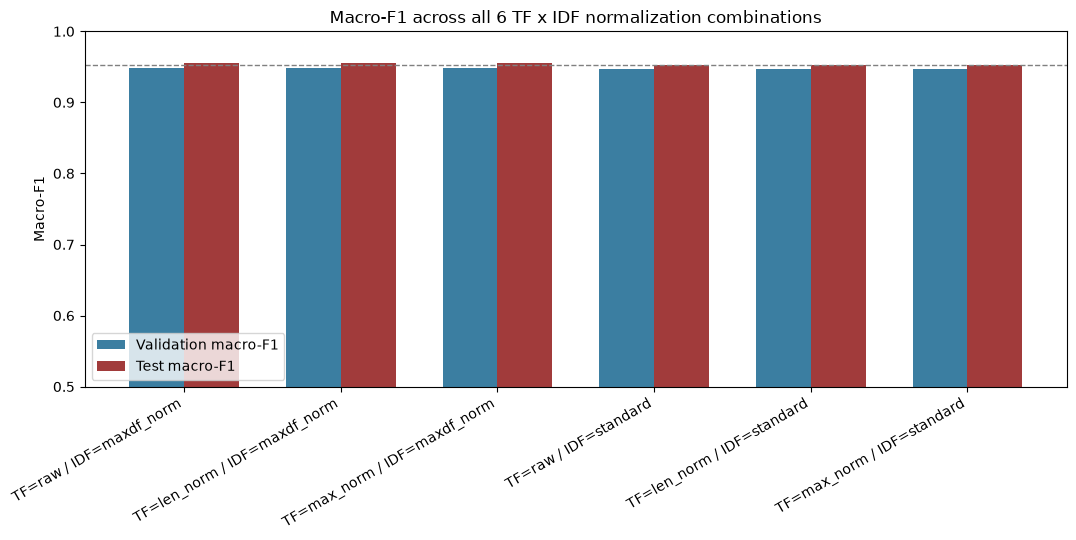

Best combination by test macro-F1: TF=raw / IDF=maxdf_norm  (test_macro_f1=0.9554)
Lab 1 baseline (TF=raw / IDF=standard): test_macro_f1=0.9532
Delta vs. baseline: +0.0022


In [13]:

display(results_df.sort_values("test_macro_f1", ascending=False)
        [["combination", "val_accuracy", "val_macro_f1", "test_accuracy", "test_macro_f1", "train_time_sec"]]
        .style.format({"val_accuracy": "{:.4f}", "val_macro_f1": "{:.4f}",
                        "test_accuracy": "{:.4f}", "test_macro_f1": "{:.4f}",
                        "train_time_sec": "{:.1f}"}))

fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(results_df))
width = 0.35
order = results_df.sort_values("test_macro_f1", ascending=False).index
ax.bar(x - width/2, results_df.loc[order, "val_macro_f1"], width, label="Validation macro-F1", color="#3B7EA1")
ax.bar(x + width/2, results_df.loc[order, "test_macro_f1"], width, label="Test macro-F1", color="#A13B3B")
ax.set_xticks(x)
ax.set_xticklabels(results_df.loc[order, "combination"], rotation=30, ha="right")
ax.set_ylabel("Macro-F1")
ax.set_title("Macro-F1 across all 6 TF x IDF normalization combinations")
ax.set_ylim(min(0.5, results_df[["val_macro_f1", "test_macro_f1"]].min().min() - 0.05), 1.0)
ax.legend()
ax.axhline(results_df.loc[results_df["combination"] == "TF=raw / IDF=standard", "test_macro_f1"].iloc[0],
           color="gray", linestyle="--", linewidth=1, label="Lab 1 baseline (test)")
plt.tight_layout()
plt.show()

best_row = results_df.sort_values("test_macro_f1", ascending=False).iloc[0]
baseline_row = results_df[(results_df["tf_mode"] == "raw") & (results_df["idf_mode"] == "standard")].iloc[0]
print(f"Best combination by test macro-F1: {best_row['combination']}  (test_macro_f1={best_row['test_macro_f1']:.4f})")
print(f"Lab 1 baseline (TF=raw / IDF=standard): test_macro_f1={baseline_row['test_macro_f1']:.4f}")
print(f"Delta vs. baseline: {best_row['test_macro_f1'] - baseline_row['test_macro_f1']:+.4f}")



## Section 12 — Per-Class Breakdown for the Best Combination

Zooming in on the languages that were hardest in Lab 1's baseline
(`gom_Deva`/`mar_Deva`/`hin_Deva`, the Devanagari confusion cluster) to see whether the
winning normalization scheme specifically helps them, or whether the gain (if any) is
spread evenly across all 23 languages.


In [14]:

best_combo_name = results_df.sort_values("test_macro_f1", ascending=False).iloc[0]["combination"]
best_test_pred = trained_models[best_combo_name]["test_pred"]

best_report, best_summary = classification_report_custom(y_test, best_test_pred, len(LABELS), target_names=LABELS)
baseline_test_pred = trained_models["TF=raw / IDF=standard"]["test_pred"]
baseline_report, baseline_summary = classification_report_custom(y_test, baseline_test_pred, len(LABELS), target_names=LABELS)

compare_df = pd.DataFrame({
    "label": LABELS,
    "baseline_f1 (TF=raw/IDF=standard)": baseline_report.set_index("label").loc[LABELS, "f1"].values,
    f"best_f1 ({best_combo_name})": best_report.set_index("label").loc[LABELS, "f1"].values,
})
compare_df["delta"] = compare_df.iloc[:, 2] - compare_df.iloc[:, 1]
display(compare_df.sort_values("delta"))

print("\nWeak-cluster focus (Lab 1's hardest languages):")
for lab in ["gom_Deva", "mar_Deva", "hin_Deva"]:
    row = compare_df[compare_df["label"] == lab].iloc[0]
    print(f"  {lab:>10s}: baseline F1={row.iloc[1]:.4f}  ->  best-combo F1={row.iloc[2]:.4f}  (delta={row['delta']:+.4f})")


,label,baseline_f1 (TF=raw/IDF=standard),best_f1 (TF=raw / IDF=maxdf_norm),delta
11,mar_Deva,0.756522,0.751092,-0.005430
13,npi_Deva,0.995516,0.991071,-0.004444
20,urd_Arab,0.986547,0.986547,0.000000
19,tel_Telu,1.000000,1.000000,0.000000
18,tam_Taml,0.995475,0.995475,0.000000
17,snd_Deva,0.995516,0.995516,0.000000
15,pan_Guru,1.000000,1.000000,0.000000
14,ory_Orya,1.000000,1.000000,0.000000
12,mni_Mtei,0.972222,0.972222,0.000000
21,khasi,0.948718,0.948718,0.000000



Weak-cluster focus (Lab 1's hardest languages):
    gom_Deva: baseline F1=0.6832  ->  best-combo F1=0.7053  (delta=+0.0221)
    mar_Deva: baseline F1=0.7565  ->  best-combo F1=0.7511  (delta=-0.0054)
    hin_Deva: baseline F1=0.8963  ->  best-combo F1=0.9008  (delta=+0.0046)



## Section 13 — Discussion: Why did the winning combination win?

*(Fill this in after running on the real dataset — the reasoning below explains what
to look for, since the actual winner depends on real corpus statistics.)*

* **If TF‑`len_norm` helps:** it means raw counts were letting **longer sentences
  dominate** the feature space simply by containing more repeated word/char n‑grams
  in absolute terms — dividing by sentence length puts short and long sentences on
  equal footing, which usually helps if sentence length varies a lot within a
  language (it does here: Section 5 of Lab 1 showed a wide character‑length spread).
* **If TF‑`max_norm` helps:** it means a few highly‑repetitive local patterns (e.g. a
  word or particle repeated several times in one sentence) were previously dominating
  that sentence's vector; max‑normalization caps their influence relative to
  everything else the sentence contains, which can help when the *most frequent*
  word in a sentence is a low‑information function word (postpositions, conjunctions)
  rather than a genuinely discriminative one.
* **If IDF‑`maxdf_norm` helps:** it means compressing the IDF scale (anchoring "how
  rare" on the most common word rather than the full corpus size) reduced the
  over‑penalization of moderately common — but still useful — function words/particles
  that differ between closely related languages (e.g. distinct postpositions in
  Marathi vs. Konkani), which the standard IDF formula might have suppressed too
  aggressively relative to ultra‑rare, less generalizable n‑grams.
* **If nothing beats the Lab 1 baseline:** that is itself a valid, useful finding —
  it would indicate the L2 row‑normalization Lab 1 already applied was doing most of
  the useful normalization work, and these additional TF/IDF‑level normalizations
  are, for this dataset, mostly redundant with (or even in mild tension with) that
  final step.

Re-run Section 12's per-class delta table specifically for `gom_Deva`/`mar_Deva`/
`hin_Deva` to check which of these explanations actually applies to your run.
